## Exposing Tools and M4 RAG Pipeline using MCP

In [2]:
%%writefile wealthpilot_mcp_server.py
"""A FastMCP server exposing WealthPilot database tables over stdio."""

import sqlite3
import sys
from fastmcp import FastMCP

import os
from qdrant_client import QdrantClient
from qdrant_client.models import Filter, FieldCondition, MatchValue
import hashlib, json, time
from langchain_google_genai import GoogleGenerativeAIEmbeddings

from dotenv import load_dotenv
load_dotenv(".env", override=True)

QDRANT_URL    = os.getenv("QDRANT_URL")
QDRANT_KEY    = os.getenv("QDRANT_API_KEY")
GEMINI_API_KEY   = os.getenv("GEMINI_API_KEYKEY")

client = QdrantClient(url=QDRANT_URL, api_key=QDRANT_KEY)
COLLECTION = "wealth_realdocs"
_base = GoogleGenerativeAIEmbeddings(model="gemini-embedding-001")

CACHE_DIR = ".embcache"
os.makedirs(CACHE_DIR, exist_ok=True)

mcp = FastMCP("wealthpilot-workspace")

def _ckey(text):  return hashlib.sha1(("gemini-embedding-001::" + text).encode("utf-8")).hexdigest()
def _cget(text):
    p = os.path.join(CACHE_DIR, _ckey(text) + ".json")
    if os.path.exists(p):
        with open(p) as f:
            return json.load(f)
    return None
def _cput(text, vec):
    with open(os.path.join(CACHE_DIR, _ckey(text) + ".json"), "w") as f:
        json.dump(vec, f)

def _embed_query(text):
    v = _cget(text)
    if v is None:
        v = _base.embed_query(text)
        _cput(text, v)
    return v

def _connect():
    conn = sqlite3.connect("wealthpilot.db")
    conn.row_factory = sqlite3.Row
    return conn

@mcp.tool
def applicant_details(applicant_id: str) -> dict:
    """Retrieve applicant financial and operating fields for an applicant ID."""
    conn = _connect()
    row = conn.execute("""
        SELECT ebitda_inr, existing_debt_inr, sector, months_operating, annual_revenue_inr
        FROM applicants_table WHERE applicant_id = ?
    """, (applicant_id,)).fetchone()
    conn.close()
    if row is None:
        return {}
    return dict(row)

@mcp.tool
def loan_application_details(applicant_id: str) -> dict:
    """Retrieve loan and collateral fields for an applicant ID."""
    conn = _connect()
    row = conn.execute("""
        SELECT requested_amount_inr, requested_tenor_months,
               existing_annual_debt_service_inr, collateral_value_inr,
               current_assets_inr, current_liabilities_inr,
               declared_annual_revenue_inr
        FROM loan_applications_table WHERE applicant_id = ?
    """, (applicant_id,)).fetchone()
    conn.close()
    if row is None:
        return {}
    return dict(row)


@mcp.tool
def bureau_reports(applicant_id: str) -> dict:
    """Retrieve bureau score and adverse-credit fields for an applicant ID."""
    conn = _connect()
    row = conn.execute("""
        SELECT bureau_score, active_trade_lines, dpd_90_ever, written_off_amount_inr
        FROM bureau_table WHERE applicant_id = ?
    """, (applicant_id,)).fetchone()
    conn.close()
    if row is None:
        return {}
    return dict(row)


@mcp.tool
def risk_grades(dscr: float, bureau_score: int) -> dict:
    """Retrieve the risk grade for a DSCR and bureau score."""
    conn = _connect()
    row = conn.execute("""
        SELECT * FROM risk_grades_table
        WHERE ? >= min_dscr AND ? >= min_bureau_score
        ORDER BY grade ASC LIMIT 1
    """, (dscr, bureau_score)).fetchone()
    conn.close()
    if row is None:
        return {}
    return dict(row)


@mcp.tool
def sector_policies(sector_name: str) -> dict:
    """Retrieve the policy floor and tenor cap for a sector."""
    conn = _connect()
    row = conn.execute("""
        SELECT dscr_floor, max_tenor_months AS sector_max_tenor_months, at_sector_cap
        FROM sector_policies_table WHERE sector = ?
    """, (sector_name,)).fetchone()
    conn.close()
    if row is None:
        return {}
    return dict(row)

@mcp.tool
def query_knowledge_base(query, k=3, source=None):
    """Fetch information from the knowledge base which is based on the company internal documents"""
    qfilter = Filter(must=[FieldCondition(key="source", match=MatchValue(value=source))]) if source else None

    hits = client.query_points(collection_name=COLLECTION, query=_embed_query(query),
                               query_filter=qfilter, limit=k).points
    return [h.payload['text'] for h in hits]

if __name__ == "__main__":
    print("[wealthpilot_mcp_server] starting on stdio", file=sys.stderr)
    mcp.run(transport="stdio", show_banner=False)


Overwriting wealthpilot_mcp_server.py


In [3]:
import sys, os, json
from langchain_mcp_adapters.client import MultiServerMCPClient

SERVER_PATH = os.path.abspath("wealthpilot_mcp_server.py")

# ---------------------------------------------------------------------------------------------

import sys, io
import mcp.client.stdio as _mcp_stdio
import langchain_mcp_adapters.sessions as _mcp_sessions

# 1. Open the log once, not once per cell re-run (the old version leaked a file descriptor each time).
if "MCP_SERVER_LOG" not in globals() or MCP_SERVER_LOG.closed:
    MCP_SERVER_LOG = open("mcp_server.log", "a", encoding="utf-8")

# 2. Recover the true original. A patched function carries a marker, so we can unwrap it
#    instead of trusting whatever is currently bound to the module attribute.
_current = _mcp_stdio.stdio_client
_true_original = getattr(_current, "__pre_patch__", None) or _current
if getattr(_true_original, "__module__", "") == "__main__":
    raise RuntimeError("stdio_client is already patched by an unmarked patch — restart the kernel.")
_mcp_stdio._pre_patch_stdio_client = _true_original

# 3. Bind `original` and `log` as keyword-only DEFAULTS -> evaluated once, at def time.
#    They can never be re-resolved through the notebook's global namespace.
def _stdio_client_logging_to_file(server, errlog=None, *, _orig=_true_original, _log=MCP_SERVER_LOG):
    return _orig(server, errlog if errlog is not None else _log)

_stdio_client_logging_to_file.__pre_patch__ = _true_original   # makes re-runs safe forever

_mcp_stdio.stdio_client = _stdio_client_logging_to_file
_mcp_sessions.stdio_client = _stdio_client_logging_to_file

In [4]:
mcp_client = MultiServerMCPClient({
    "project": {
        "transport": "stdio",     
        "command": sys.executable, 
        "args": [SERVER_PATH],
    }
})

mcp_tools = await mcp_client.get_tools()
TOOLS_BY_NAME = {t.name: t for t in mcp_tools}

print("DISCOVERED TOOLS")
print("-------------------------------------------------------")
for t in mcp_tools:
    print(f"  {t.name}{tuple(t.args)}")
    print(f"      {t.description.splitlines()[0]}")

DISCOVERED TOOLS
-------------------------------------------------------
  applicant_details('applicant_id',)
      Retrieve applicant financial and operating fields for an applicant ID.
  loan_application_details('applicant_id',)
      Retrieve loan and collateral fields for an applicant ID.
  bureau_reports('applicant_id',)
      Retrieve bureau score and adverse-credit fields for an applicant ID.
  risk_grades('dscr', 'bureau_score')
      Retrieve the risk grade for a DSCR and bureau score.
  sector_policies('sector_name',)
      Retrieve the policy floor and tenor cap for a sector.
  query_knowledge_base('query', 'k', 'source')
      Fetch information from the knowledge base which is based on the company internal documents


In [48]:
#Check - manual invoking a tool
await TOOLS_BY_NAME["applicant_details"].ainvoke({"applicant_id": "ASH-A-00001"})

[{'type': 'text',
  'text': '{"ebitda_inr":16713441,"existing_debt_inr":34114701,"sector":"Auto Components","months_operating":45,"annual_revenue_inr":85000000}',
  'id': 'lc_2e019ef5-0be3-4fac-9bdc-ba816edbda53'}]

In [ ]:
NLQ = "What rate would we indicate to a B2 applicant, what's the longest tenor we'd offer them, and how much collateral?"

#Check - manual invoking a tool
await TOOLS_BY_NAME["query_knowledge_base"].ainvoke({"query": NLQ, "k": 3})

[{'type': 'text',
  'text': '["4.2 Risk Grading Matrix The underwriting system shall hold and enforce the following grading grid without exception: 1. Grade A1 * Quantitative Criteria: DSCR $\\\\ge 2.00$ AND Bureau Score $\\\\ge 750$. * Interest Rate Spread: 150 basis points over base rate (Indicative Rate: 11.00%). * Maximum Tenor: 84 months. * Collateral Cover: 0%. 2. Grade A2 * Quantitative Criteria: DSCR $\\\\ge 1.75$ AND Bureau Score $\\\\ge 700$. * Interest Rate Spread: 200 basis points over base rate (Indicative Rate: 11.50%). * Maximum Tenor: 72 months. * Collateral Cover: 25%. 3. Grade B1 * Quantitative Criteria: DSCR $\\\\ge 1.50$ AND Bureau Score $\\\\ge 650$. * Interest Rate Spread: 275 basis points over base rate (Indicative Rate: 12.25%). * Maximum Tenor: 60 months. * Collateral Cover: 50%. 4. Grade B2 * Quantitative Criteria: DSCR $\\\\ge 1.35$ AND Bureau Score $\\\\ge 600$. * Interest Rate Spread: 350 basis points over base rate (Indicative Rate: 13.00%). * Maximum Teno

## Underwriting team with a Critic/Reviewer

The graph uses a separate **Analyst**, **Risk Reviewer**, **Compliance Reviewer**, and **Critic**. The critic can send the draft back to the Analyst, but revision_count is capped by `MAX_REVISIONS`.

In [5]:
import os, sys, time
from dotenv import load_dotenv
load_dotenv(".env", override=True)

from langchain_litellm import ChatLiteLLM
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage, ToolMessage
from pydantic import BaseModel, Field

GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")
LLM_MODEL = os.getenv("LLM_MODEL", "gemini/gemini-flash-lite-latest")
chat_model = ChatLiteLLM(model=LLM_MODEL, temperature=0, api_key=os.getenv("GEMINI_API_KEY", GEMINI_API_KEY))

c:\Users\bharath-asus\Documents\LEARNING\Documentation\Articles\agentic_ai_projects\wealth_pilot\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
LLM_CALL_PAUSE_SECONDS = 3.0

def _probe_model() -> bool:
    """One real, tiny call. A present-but-invalid key fails HERE, once, with a clear message -
    instead of failing inside a graph node twenty cells later where it looks like a LangGraph bug."""
    try:
        chat_model.invoke([HumanMessage(content="Reply with the single word: ok")])
        return True
    except Exception as e:
        print(f"  model unavailable ({type(e).__name__}: {str(e)[:110]})")
        return False

LLM_ENABLED = _probe_model()

def ask(system: str, user: str) -> str | None:
    """Plain text -> text. Returns None (never raises) so callers can fall back deterministically."""
    if not LLM_ENABLED:
        return None
    try:
        msgs = [SystemMessage(content=system), HumanMessage(content=user)]
        return chat_model.invoke(msgs).content.strip()
    except Exception as e:
        print(f"  [model call failed: {type(e).__name__}] falling back")
        return None
    finally:
        time.sleep(LLM_CALL_PAUSE_SECONDS)  # give the rate limit room to breathe before the next call


_STRUCTURED_CACHE: dict[type, object] = {}

def ask_structured(system: str, user: str, schema: type[BaseModel]) -> BaseModel | None:
    """Text -> a VALIDATED Pydantic object. Returns None on any failure. """
    if not LLM_ENABLED:
        return None
    try:
        runnable = _STRUCTURED_CACHE.setdefault(schema, chat_model.with_structured_output(schema))
        return runnable.invoke([SystemMessage(content=system), HumanMessage(content=user)])
    except Exception as e:
        print(f"  [structured call failed: {type(e).__name__}] falling back")
        return None
    finally:
        time.sleep(LLM_CALL_PAUSE_SECONDS)  # give the rate limit room to breathe before the next call

print("LLM_ENABLED :", LLM_ENABLED, "|", LLM_MODEL if LLM_ENABLED else "running on deterministic fallbacks")

LLM_ENABLED : True | gemini/gemini-flash-lite-latest


In [7]:
from IPython.display import Image, display, Markdown

def show_graph(app, title: str = ""):
    if title:
        print(title)
        print("-" * len(title))
    try:
        display(Image(app.get_graph().draw_mermaid_png()))      # real PNG, inline
    except Exception as e:
        print(f"(mermaid.ink unavailable - {type(e).__name__}; Mermaid source below)")
        display(Markdown("```mermaid\n" + app.get_graph().draw_mermaid() + "\n```"))

print("show_graph() ready.")

show_graph() ready.


In [8]:
# Team state, agent scopes, and the enforcement decorator.
from typing import TypedDict, Annotated, Literal, List
from operator import add
import inspect, re, json
from langgraph.graph import StateGraph, START, END

MAX_REVISIONS = 2          # the loop budget. Everything about convergence hangs off this number.

class UnderWritingState(TypedDict):
    raw: str
    proposed_annual_debt_service_inr: float
    dscr: float
    sector_dscr_floor: float
    meets_dscr_floor: bool
    leverage_ratio: float
    current_ratio: float
    revenue_variance_pct: float
    internal_grade: Literal["A1", "A2", "B1", "B2", "C1", "C2", "D1", "D2"]
    indicative_rate_pct: float
    reason_codes: str
    risk_band: Literal["approve", "borderline", "decline"]
    approval_authority: Literal["Credit Officer", "Board Credit Committee", "Credit Committee"]
    auto_approve_allowed: bool
    requires_human_signoff: bool
    loan_application: dict
    missing_fields: List[str]
    log: Annotated[list[str], add]
    revision_count: int
    critic_decision: Literal[None, "pass", "review"]
    critic_feedback: str
    final_status: str
    

In [9]:
# write scope
AGENT_SCOPES = {
    "analyst": {"loan_application", "revision_count", "critic_decision"},
    "risk_reviewer": {
        "proposed_annual_debt_service_inr",
        "dscr", "sector_dscr_floor", "meets_dscr_floor", "leverage_ratio",
        "current_ratio", "revenue_variance_pct", "internal_grade", "indicative_rate_pct",
        "reason_codes", "risk_band"
        },
    "compliance_reviewer": {"approval_authority", "auto_approve_allowed", "requires_human_signoff", 'final_status'},
    "critic": {"critic_decision", "critic_feedback", "final_status"},
}

In [10]:
def scoped(role: str):
    """Enforce write permissions. A violation raises instead of silently corrupting state.

    Handles async nodes too - in Lab B the researcher becomes async (it awaits an MCP call), and
    a decorator that only understood sync functions would wrap a coroutine and fail obscurely."""
    allowed = AGENT_SCOPES[role] | {"log"}

    def enforce(update):
        illegal = set(update) - allowed
        if illegal:
            raise PermissionError(
                f"agent '{role}' wrote outside its scope: {sorted(illegal)}; allowed={sorted(allowed)}")
        return update

    def decorate(fn):
        if inspect.iscoroutinefunction(fn):
            async def awrapper(state):
                return enforce(await fn(state))
            awrapper.__name__ = fn.__name__
            return awrapper
        def wrapper(state):
            return enforce(fn(state))
        wrapper.__name__ = fn.__name__
        return wrapper
    return decorate

In [11]:
## Systems Prompts for Agents

SYSTEM_PROMPTS = {
 "analyst": "You read the raw loan application and extract critical values required for underwriting. " 
            "If they are missing, set them to an empty string.", 
 "risk_reviewer": "You receive the loan application in JSON format. If there are missing fields, "
                    " use the available tools to fetch the values for those missing fields.",
 "critic": "You review the generated underwriting report. Refer to the knowledge base, fetch the documents "
             "and verify that the risk grade assigned to the loan application is accurate. "
}

In [12]:
# read scope
def context_for(role: str, state: UnderWritingState) -> dict:
    """READ scoping: hand each agent only the slice it needs. """

    if role == "analyst":      return {"raw": state["raw"], "missing_fields": state["missing_fields"]}
    if role=='risk_reviewer':  return state['loan_application']
    if role=='compliance_reviewer': return {'risk_band': state['risk_band'],
                                            'requested_amount': state["loan_application"]['requested_amount_inr'],
                                            "internal_grade": state['internal_grade']
                                            }
    if role == "critic":   return {"dscr": state["dscr"],
                                    "bureau_score": state["loan_application"]['bureau_score'],
                                       "internal_grade": state['internal_grade']
                                       }
    return {}

In [13]:
# The typed contracts each agent must return

class Analyst(BaseModel):
    """The analyst's output."""
    applicant_id: str = Field(description="Unique identifier for the applicant. It should be ASH-A-XXXXX where X is a digit")
    application_id: str  = Field(description="Unique identifier for the applicantion. It should be ASH-L-XXXXX where X is a digit")
    sector: str = Field(description="Industry sector of the applicant")
    requested_amount_inr: float = Field(description="Requested loan amount in INR")
    requested_tenor_months: int = Field(description="Requested loan tenor in months")
    bureau_score: int = Field(description="Credit bureau score")
    ebitda_inr: int = Field(description="EBITDA in INR")
    existing_annual_debt_service_inr: int = Field(description="Existing annual debt service in INR")
    months_operating: int = Field(description="Number of months operating")
    annual_revenue_inr: int = Field(description="Verified Annual Revenue in INR")
    existing_debt_inr: int = Field(description="Existing debt in INR")
    current_assets_inr: int = Field(description="Current assets in INR")
    current_liabilities_inr: int = Field(description="Current liabilities in INR")
    collateral_value_inr: int = Field(description="Collateral value in INR")

class Critic(BaseModel):
    """The critic's output"""
    critic_decision: Literal["pass", "review"] = Field(description="Reply with a single word 'Pass' if all the tests are passed else 'review'")
    critic_feedback: str = Field(description="one short sentence explaining the verdict")

In [14]:
@scoped("analyst")
def analyst_node(state: UnderWritingState) -> dict:
    ctx = context_for("analyst", state)
    is_revision = state["critic_decision"] == 'review'

    CORRECTION_PROMPT = ""
    if is_revision:
        CORRECTION_PROMPT = f"And fix these issues {state['critic_feedback']}"

    out = ask_structured(
        SYSTEM_PROMPTS["analyst"] + CORRECTION_PROMPT,
        f"Raw Application:\n{ctx['raw']}",
        Analyst)

    loan_app_dict = out.model_dump()
    loan_app_dict.update(
        {
            "declared_annual_revenue_inr": "",
            "active_trade_lines": "",
            "dpd_90_ever": "",
            "written_off_amount_inr": "",
            "dscr_floor": "",
            "sector_max_tenor_months": "",
            "at_sector_cap": ""
        }
    )
    return {'loan_application' : loan_app_dict,
            "revision_count": state["revision_count"] + (1 if is_revision else 0),
            "log": ["Extracted data from the raw intake record"],
            "critic_decision": ""
            }

In [16]:
# Validation node - Pure python function
def validate_node(state: UnderWritingState) -> dict:
    missing = []
    for field in state["loan_application"]:
        if state["loan_application"][field] in [None, ""]:
            missing.append(field)
    return {"missing_fields": missing, "log": [f"Validator: {len(missing)} fields are missing"]}

# Route node - Pure python function
def route_after_validation(state: UnderWritingState) -> str:
    if state["missing_fields"]: return "fetch"
    else: return "risk_review"

In [17]:
def parse_tool_result(raw):
    """MCP tool results arrive as CONTENT BLOCKS, not plain Python values."""
    if isinstance(raw, list) and raw and isinstance(raw[0], dict) and "text" in raw[0]:
        raw = "".join(b.get("text", "") for b in raw if b.get("type") == "text")
    if isinstance(raw, str):
        try:
            return json.loads(raw)
        except json.JSONDecodeError:
            return raw
    return raw

In [18]:
# Tool calling node - uses LLM
async def tool_call_and_execute_node(state: UnderWritingState) -> dict:
    """The policy node: look at the missing fields so far, decide to call a tool to fetch the field value."""

    current_dict = state['loan_application']
    messages = [SystemMessage(content="You fill the missing fields. Look at all the missing fields and use the tool available to you"
                          "to fetch the value for those fields."),
    HumanMessage(content=f"Applicant ID is {current_dict['applicant_id']}, sector is {current_dict['sector']}. Missing fields are: {state['missing_fields']}")]

    if LLM_ENABLED:
        model = chat_model.bind_tools(mcp_tools)
        response = await model.ainvoke(messages)
        if response.tool_calls:
            log = []
            for c in response.tool_calls:
                tool_call_result = await TOOLS_BY_NAME[c["name"]].ainvoke(c["args"])
                current_dict.update(parse_tool_result(tool_call_result[0]['text']))
                log.append(f"Tool call: {c['name']} with arg {c['args']}.")  
            return {'loan_application': current_dict, "missing_fields": [], 'log': log}


In [19]:
# Python function with a single tool call

@scoped("risk_reviewer")
async def risk_reviewer_node(state: UnderWritingState)-> dict:
    ctx = context_for("risk_reviewer", state)
    codes=[]

    r = 14.0 / 1200
    emi = ctx['requested_amount_inr'] * r / (1 - (1 + r) ** -ctx['requested_tenor_months'])
    proposed =  round(emi * min(12, ctx['requested_tenor_months']))
        
    if ctx['existing_annual_debt_service_inr'] is not None and proposed is not None:
        dscr = round(ctx['ebitda_inr'] / (ctx['existing_annual_debt_service_inr'] + proposed),2)
    
    tool_call_result = await TOOLS_BY_NAME["risk_grades"].ainvoke({'dscr': dscr, 'bureau_score': ctx['bureau_score']})
    risk_grade_dict = parse_tool_result(tool_call_result[0]['text'])

    if ctx['ebitda_inr'] and ctx['existing_debt_inr'] is not None:
        leverage = round((ctx['existing_debt_inr'] + ctx['requested_amount_inr']) / ctx['ebitda_inr'], 2)

    if ctx['current_assets_inr'] is not None and ctx['current_liabilities_inr']:
        current_ratio = round(ctx['current_assets_inr'] / ctx['current_liabilities_inr'], 2)

    if ctx["declared_annual_revenue_inr"] is not None and ctx["annual_revenue_inr"]:
        variance = round(100 * (ctx["declared_annual_revenue_inr"] - ctx["annual_revenue_inr"]) / ctx["annual_revenue_inr"], 1)
    
    # adding reason codes
    if dscr is not None and dscr < ctx['dscr_floor']:
        codes.append("DSCR_BELOW_FLOOR")

    thin = (ctx['months_operating'] is not None and ctx['months_operating'] < 24) or (
        ctx['active_trade_lines'] is not None and ctx['active_trade_lines'] < 1
    )
    if thin:
        codes.append("THIN_FILE")
    adverse = ctx['bureau_score'] is not None and ctx['bureau_score'] < 450
    if adverse:
        codes.append("ADVERSE_BUREAU")
    if ctx['dpd_90_ever'] or ctx['written_off_amount_inr'] >= 500_000:
        codes.append("PAST_DELINQUENCY")
    if variance is not None and abs(variance) > 10:
        codes.append("DOC_MISMATCH")
    if variance is not None and abs(variance) > 25:
        codes.append("FRAUD_HOLD")
    if ctx['at_sector_cap']==1:
        codes.append("SECTOR_CAP")
    if leverage is not None and leverage > 6.0:
        codes.append("LEVERAGE_ABOVE_LIMIT")
    if current_ratio is not None and current_ratio < 1.10:
        codes.append("LIQUIDITY_BELOW_FLOOR")

    too_young = ctx['months_operating'] is not None and ctx['months_operating'] < 24
    decline = (dscr is not None and dscr < 1.0) or adverse or too_young or risk_grade_dict['grade'] == "D2"
    
    if not decline and risk_grade_dict['grade'] is not None:
        grade_tenor = risk_grade_dict['max_tenor_months']
        cover = risk_grade_dict['collateral_cover_pct']

        if ctx['requested_tenor_months'] > min(grade_tenor, ctx['sector_max_tenor_months']):
            codes.append("TENOR_ABOVE_LIMIT")
        if ctx['collateral_value_inr'] is not None and ctx['collateral_value_inr'] < ctx['requested_amount_inr'] * cover / 100:
            codes.append("COLLATERAL_SHORTFALL")
        if risk_grade_dict['grade'] in ("C2", "D1"):
            codes.append("GRADE_REQUIRES_REVIEW")

    incomplete = (
        dscr is None or leverage is None or current_ratio is None
        or ctx['bureau_score'] is None or ctx['months_operating'] is None
    )
    if incomplete:
        codes.append("INCOMPLETE_APPLICATION")

    if decline:
        band = "decline"
    elif codes or incomplete:
        band = "borderline"
    else:
        band = "approve"

    return {
        'proposed_annual_debt_service_inr': proposed,
        'dscr' : dscr,
        'sector_dscr_floor': ctx['dscr_floor'],
        'meets_dscr_floor' : dscr >= ctx['dscr_floor'],
        'leverage_ratio' : leverage,
        'current_ratio' : current_ratio,
        'revenue_variance_pct' : variance,
        'internal_grade': risk_grade_dict['grade'],
        'indicative_rate_pct': risk_grade_dict['indicative_rate_pct'],
        'reason_codes' : ";".join(codes) or "APPROVED_STANDARD",
        "risk_band": band,
        'log': ["risk reviewer: calculated critical metrics and the risk band"]
    }

In [20]:
@scoped("compliance_reviewer")
def compliance_reviewer_node(state: UnderWritingState)-> dict:
    ctx = context_for("compliance_reviewer", state)
    
    auto = (
    ctx['risk_band'] == "approve"
    and ctx['requested_amount'] <= 1_000_000
    and ctx['internal_grade'] in ("A1", "A2", "B1", "B2", "C1") 
)
    _AUTHORITIES = [
    ("Credit Officer", 1_000_000),
    ("Credit Committee", 5_000_000),
    ("Board Credit Committee", None),
    ]

    return {
        "approval_authority": next(name for name, limit in _AUTHORITIES if limit is None or ctx['requested_amount']  <= limit),
        "auto_approve_allowed": auto,
        "requires_human_signoff": not auto,
        "final_status" : "Compliance Review passed. Underwriting report is ready!",
        "log": ["Compliance Review done"]
    }


In [21]:
## LLM as a Judge - independently verifies the assigned risk grade against the company's internal documents

@scoped("critic")
async def critic_node(state: UnderWritingState)-> dict:
    ctx = context_for("critic", state)

    query = "What is the Risk Grading matrix that the underwriting system should follow?"

    #Check - manual invoking a tool
    tool_call_result = await TOOLS_BY_NAME["query_knowledge_base"].ainvoke({"query": query, "k": 1, "source": "risk-grading"})
    kb_context = parse_tool_result(tool_call_result[0]['text'])

    out = ask_structured(
    SYSTEM_PROMPTS["critic"],
    f"Given the context:\n{kb_context}.\n\n"
    f"Verify that BOTH the criteria are met: {ctx['dscr']} >= the minimum DSCR required for {ctx['internal_grade']}"
    f"AND {ctx['bureau_score']} >=  the minimum bureau score required for {ctx['internal_grade']} ",
    Critic)

    critic_output = out.model_dump()
    if critic_output['critic_decision']=='review':
        critic_output['final_status'] = 'Revision required'
        
    return critic_output

In [ ]:
#await critic_node(current_2_dict)

{'critic_decision': 'pass',
 'critic_feedback': 'Both quantitative criteria for Grade C1 are successfully met.'}

In [22]:
# Route node - Pure python function
def route_after_critic(state: UnderWritingState) -> str:
    if state["critic_decision"]=='review' and state["revision_count"] < MAX_REVISIONS: return "revise"
    else: return "end"

In [ ]:
g = StateGraph(UnderWritingState)
g.add_node("analyse", analyst_node)
g.add_node("validate", validate_node)
g.add_node("tool_call", tool_call_and_execute_node)
g.add_node("risk_review", risk_reviewer_node)
g.add_node("compliance_review", compliance_reviewer_node)
g.add_node("critic", critic_node)
#g.add_node("finalize", finalize_node)

g.add_edge(START, "analyse")
g.add_edge("analyse", "validate")
g.add_conditional_edges("validate", route_after_validation,
                        {"fetch": "tool_call", "risk_review": "risk_review"})
g.add_edge("tool_call", "validate")
g.add_edge("risk_review", "compliance_review")
g.add_edge("compliance_review", "critic")
g.add_conditional_edges("critic", route_after_critic,
                        {"revise": "analyse", "end": END})


multi_agent_graph= g.compile()

Multi-agent underwriting LangGraph Workflow
-------------------------------------------


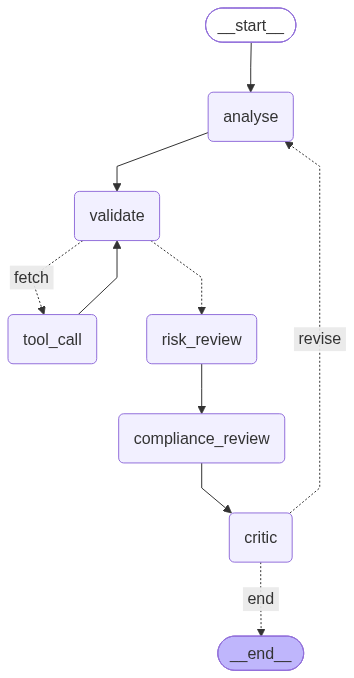

In [24]:
show_graph(multi_agent_graph, "Multi-agent underwriting LangGraph Workflow")

In [25]:
RAW_INTAKE = """{"application_id": "ASH-L-00076", "applicant_id": "ASH-A-00076", "channel": "web_form",
"received_at": "2026-07-24T11:56",
"raw_narrative": "At Douglas Industries, we have been supplying precision auto parts to tier-1 makers 
for nearly two decades now out here in Malegaon. My family has always been deeply rooted in the Jain community,
attending the main temple on MG Road every single Tuesday, and we pride ourselves on absolute honesty in business.
We are looking for 1,700,000 over 48 months to fund our new CNC machinery purchase which will boost our output.
Our annual revenue stands at 85,000,000 rupees.",
"business_name": "Douglas Industries",
"sector": "Auto Components",
"requested_amount_inr": 1700000, "requested_tenor_months": 48, 
"declared_financials": {"annual_revenue_inr": 85000000, "ebitda_inr": 10884453, "existing_debt_inr": 17983173,
"existing_annual_debt_service_inr": 2423000, "current_assets_inr": 16358000,
"current_liabilities_inr": 9068000, "months_operating": 220, "collateral_value_inr": 2316000}, 
"bureau_score": 594,
"ground_truth": {"dscr": 3.65, "meets_dscr_floor": true, "risk_band": "approve", "requires_human_signoff": true, "missing_fields": []},
"record_id": "WEALTHPILOT-00000"}"""

seed_report = {
    "raw": RAW_INTAKE,
    "proposed_annual_debt_service_inr": "",
    "dscr": "",
    "sector_dscr_floor": "",
    "meets_dscr_floor": "",
    "leverage_ratio": "",
    "current_ratio": "",
    "revenue_variance_pct": "",
    "internal_grade": "",
    "indicative_rate_pct": "",
    "reason_codes": "",
    "risk_band": "",
    "approval_authority": "",
    "auto_approve_allowed": False,
    "requires_human_signoff": True,
    "loan_application": {},
    "missing_fields": [],
    "log": [],
    "revision_count": 0,
    "critic_decision": "",
    "critic_feedback": "",
    "final_status": ""
    }

In [27]:
# Invoke the workflow
dcfg = {"configurable": {"thread_id": "committe-run"}}
report = await multi_agent_graph.ainvoke(seed_report, dcfg)

In [29]:
keys_to_extract = [
    'proposed_annual_debt_service_inr',
    'dscr',
    'sector_dscr_floor',
    'meets_dscr_floor',
    'leverage_ratio',
    'current_ratio',
    'revenue_variance_pct',
    'internal_grade',
    'indicative_rate_pct',
    'reason_codes',
    'risk_band',
    'approval_authority',
    'auto_approve_allowed',
    'requires_human_signoff',
    'revision_count',
    'critic_decision',
    'critic_feedback',
    'log',
    'final_status'
    ]

# Dictionary comprehension
final_report = {key: report[key] for key in keys_to_extract}
final_report

{'proposed_annual_debt_service_inr': 557460,
 'dscr': 3.65,
 'sector_dscr_floor': 1.35,
 'meets_dscr_floor': True,
 'leverage_ratio': 1.81,
 'current_ratio': 1.8,
 'revenue_variance_pct': 0.0,
 'internal_grade': 'C1',
 'indicative_rate_pct': 14.0,
 'reason_codes': 'APPROVED_STANDARD',
 'risk_band': 'approve',
 'approval_authority': 'Credit Committee',
 'auto_approve_allowed': False,
 'requires_human_signoff': True,
 'revision_count': 0,
 'critic_decision': 'pass',
 'critic_feedback': 'Both quantitative criteria for Grade C1 are successfully met.',
 'log': ['Extracted data from the raw intake record',
  'Validator: 7 fields are missing',
  "Tool call: applicant_details with arg {'applicant_id': 'ASH-A-00076'}.",
  "Tool call: loan_application_details with arg {'applicant_id': 'ASH-A-00076'}.",
  "Tool call: bureau_reports with arg {'applicant_id': 'ASH-A-00076'}.",
  "Tool call: sector_policies with arg {'sector_name': 'Auto Components'}.",
  'Validator: 0 fields are missing',
  'risk r